In [9]:
# Plot Banzhaf distribution by n

from kernelprob.utils.p_generator import get_p
import scipy
import matplotlib.pyplot as plt
import numpy as np

beta_shap_sym = {
    "shapley" : "Shapley",
    "beta_shapley_2_2" : "B(2,2)",
    "beta_shapley_4_4" : "B(4,4)",
    "beta_shapley_8_8" : "B(8,8)",
    "beta_shapley_16_16" : "B(16,16)",
}

beta_shap_asym = {
    "shapley" : "Shapley",
    "beta_shapley_1_2" : "B(1,2)",
    "beta_shapley_1_4" : "B(1,4)",
    "beta_shapley_1_8" : "B(1,8)",
    "beta_shapley_1_16" : "B(1,16)",
}


weighted_banzhaf = {
    "banzhaf" : "Banzhaf",
    "weighted_banzhaf_0.6" : "WB(0.6)",
    "weighted_banzhaf_0.7" : "WB(0.7)",
    "weighted_banzhaf_0.8" : "WB(0.8)",
    "weighted_banzhaf_0.9" : "WB(0.9)",
}


weightings = {
    "Symmetric Beta Shapley" : beta_shap_sym,
    "Asymmetric Beta Shapley" : beta_shap_asym,
    "Weighted Banzhaf" : weighted_banzhaf,
}

linestyles = ['-', '--', '-.', ':', (5, (10, 3))]
cb_colors = [
    "#E69F00",  # Orange
    "#56B4E9",  # Sky Blue
    "#009E73",  # Bluish Green
    "#0072B2",  # Blue
    "#D55E00",  # Vermillion
    "#CC79A7",  # Reddish Purple
]

def plot_probabilistic_values(n, figsize):
    # 3 plots in a row
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    nums = scipy.special.binom(n-1, np.arange(n))
    for plot_idx, (weightings_name, weighting_dict) in enumerate(weightings.items()):
        ax = axs[plot_idx]
        for idx, (weighting, weighting_name) in enumerate(weighting_dict.items()):
            p = get_p(n, weighting)
            ax.plot(np.arange(n), p, label=weighting_name, linestyle=linestyles[idx], color=cb_colors[idx])
        ax.set_title(weightings_name + fr" ($n={n}$)")
        ax.set_xlabel(r"$|S|$")
        if plot_idx == 0:
            ax.set_ylabel(r"$p_{|S|}$")
        ax.set_yscale('log')
        ax.legend()

    plt.tight_layout()
    plt.savefig("images/probabilistic_values.pdf", bbox_inches='tight', dpi=300)

import scipy

def compute_bn(p, n):
    valid_sizes = np.array(list(range(n+1)))

    sum1, sum2 = 0, 0
    for ell in range(n):
        sum1 += scipy.special.binom(n-1, ell) * p[ell]**2
        if ell >= 1:
            sum2 += scipy.special.binom(n-2, ell-1) * (p[ell]-p[ell-1])**2
    an = 2*sum1 - sum2
    bn = sum2 / an
    return bn

def compute_square_prob_sum(p, n):
    total = (p[0]*n)**2 + (p[-1]*n)**2
    for size in range(1, n-1):
        total += (p[size-1] * size - p[size] * (n - size))**2 * scipy.special.binom(n, size)
    return total

def plot_bn(ns, figsize, plot_sum=False):
    # 3 plots in a row
    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for plot_idx, (weightings_name, weighting_dict) in enumerate(weightings.items()):
        ax = axs[plot_idx]
        for idx, (weighting, weighting_name) in enumerate(weighting_dict.items()):
            bns = []
            for n in ns:
                p = get_p(n, weighting)
                if plot_sum:
                    bns += [compute_square_prob_sum(p, n)]
                else:
                    bns += [compute_bn(p, n)]
            ax.plot(ns, bns, label=weighting_name, linestyle=linestyles[idx], color=cb_colors[idx])
        ax.set_title(weightings_name)
        ax.set_xlabel(r"$n$")
        if plot_idx == 0:
            ax.set_ylabel(r"$b_n$" if not plot_sum else r"Prob Square Sum")
        ax.set_xscale('log')
        #ax.set_yscale('log')
        ax.legend()

    plt.tight_layout()
    try:
        plt.savefig("images/bn.pdf", bbox_inches='tight', dpi=300)
    except:
        plt.show()



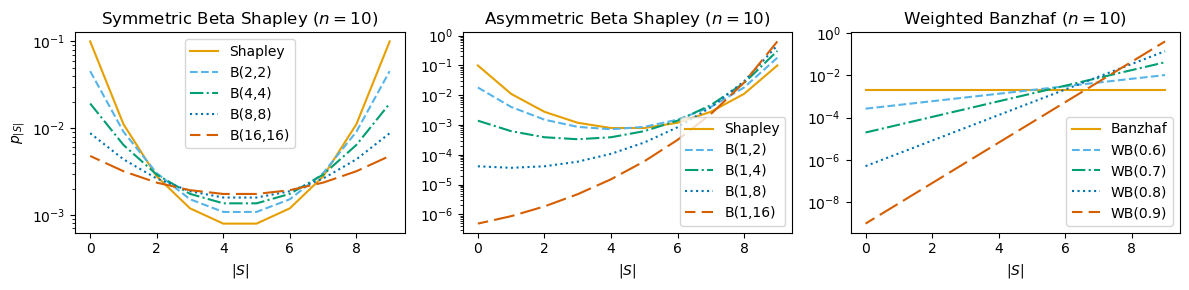

In [6]:
figsize = (12,3)
#plot_bn(ns=list(range(1,501)), figsize=figsize)
#plot_bn(ns=list(range(1,501, 1)), figsize=figsize, plot_sum=True)

plot_probabilistic_values(n=10, figsize=figsize)


/var/folders/0n/hqwrwrp96x3g_q8dnhlmvghh0000gn/T/ipykernel_41710/3303756769.py:26: RuntimeWarning: invalid value encountered in sqrt
  w[ell+1] = np.sqrt(numerator / (denominator1 + denominator2))


0.4883022086877885


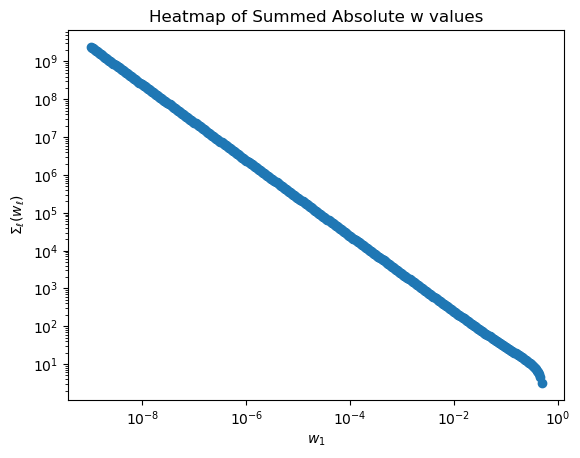

In [7]:
weighting_name = "weighted_banzhaf_0.9"
weighting_name = "shapley"
weighting_name = "beta_shapley_1_1"
#weighting_name = "banzhaf"
#weighting_name = "beta_shapley_1_16"
# Import scipy binom function
import scipy

def compute_weight_norm(w, p):
    # Normalize the weights
    c_sq = 0
    for ell in range(n):
        c_sq += scipy.special.binom(n-1, ell) * p[ell] ** 2 * (1 / w[ell] ** 2 + 1/w[ell+1] ** 2)
    return np.sqrt(c_sq)

def compute_weights(w1, p):
    n = len(p)
    w = np.zeros(n+1)
    w[0] = 1
    w[1] = w1
    # Solve for the rest of the weights
    for ell in range(1, n):
        numerator = p[ell]**2 * w[ell]**2 * w[ell-1]**2
        denominator1 = 2 * p[ell] * p[ell-1] * w[ell-1]**2
        denominator2 = -1*p[ell-1]**2 * w[ell]**2
        w[ell+1] = np.sqrt(numerator / (denominator1 + denominator2))

    c = compute_weight_norm(w, p)
    # Check if c is nan
    if not np.isnan(c):
        assert np.allclose(compute_weight_norm(w*c, p), 1)
    return w*c

def find_w1(p, start=10e-10, stop=10e10, num=1000):
    # all possible values of w1 
    valid_w1s = []
    sums = []
    for w1 in np.geomspace(start, stop, num):
        w = compute_weights(w1, p)
        if np.isnan(w).any(): continue
        valid_w1s.append(w1)
        sums.append(np.sum(w)) 
    # find the w1 so that the log_sum is closest to 0
    closest_idx = np.argmin(np.abs(np.log10(np.array(sums))))
    return valid_w1s[closest_idx]

n = 8
p = get_p(n, weighting_name)

print(find_w1(p))

# try log increasing values of b0 and b1
val_ranges = np.geomspace(10e-10, 10e10, 1000)
# all possible values of b0 and b1
w = np.zeros(n+1)
saved_w = np.zeros(len(val_ranges))
for w1_idx, w1 in enumerate(val_ranges):
    w = compute_weights(w1, p)
    saved_w[w1_idx] = np.sum(w)
        
# Plot the heatmap with labeled axes
plt.scatter(val_ranges, saved_w)
plt.xscale('log')
plt.yscale('log')

plt.xlabel(r"$w_1$")
plt.ylabel(r"$\Sigma_\ell(w_\ell)$")
plt.title("Heatmap of Summed Absolute w values")
plt.show()

In [8]:
for weighting in weightings:
    for weighting_name in weightings[weighting]:
        print(weighting_name)
        n = 100
        p = get_p(n, weighting_name)
        b = [1/np.sqrt(p[0]*p[1]),1/np.sqrt(p[1])]
        for ell in range(1, n):
            numerator = p[ell]**2 * b[ell-1]**2 * b[ell]**2
            denominator1 = 2 * p[ell] * p[ell-1] * b[ell-1]**2
            denominator2 = -1*p[ell-1]**2 * b[ell]**2
            b_ell_plus = np.sqrt(numerator / (denominator1 + denominator2))
            b.append(b_ell_plus)
        print(p)
        print(b)
        print()

shapley
[1.00000000e-02 1.01010101e-04 2.06143063e-06 6.37555866e-08
 2.65648277e-09 1.39814883e-10 8.92435422e-12 6.71725587e-13
 5.84109206e-14 5.77690423e-15 6.41878248e-16 7.93332666e-17
 1.08181727e-17 1.61650857e-18 2.63152558e-19 4.64386866e-20
 8.84546412e-21 1.81172157e-21 3.97694978e-22 9.32864763e-23
 2.33216191e-23 6.19941773e-24 1.74855372e-24 5.22295267e-25
 1.64935347e-25 5.49784491e-26 1.93167524e-26 7.14455226e-27
 2.77843699e-27 1.13485454e-27 4.86366233e-28 2.18512366e-28
 1.02829349e-28 5.06472911e-29 2.60910287e-29 1.40490155e-29
 7.90257121e-30 4.64119261e-30 2.84460192e-30 1.81867992e-30
 1.21245328e-30 8.42552279e-31 6.10124064e-31 4.60269031e-31
 3.61639953e-31 2.95887234e-31 2.52052088e-31 2.23517890e-31
 2.06324206e-31 1.98233060e-31 1.98233060e-31 2.06324206e-31
 2.23517890e-31 2.52052088e-31 2.95887234e-31 3.61639953e-31
 4.60269031e-31 6.10124064e-31 8.42552279e-31 1.21245328e-30
 1.81867992e-30 2.84460192e-30 4.64119261e-30 7.90257121e-30
 1.40490155e-29 

/var/folders/0n/hqwrwrp96x3g_q8dnhlmvghh0000gn/T/ipykernel_41710/294386161.py:8: RuntimeWarning: overflow encountered in scalar multiply
  numerator = p[ell]**2 * b[ell-1]**2 * b[ell]**2
/var/folders/0n/hqwrwrp96x3g_q8dnhlmvghh0000gn/T/ipykernel_41710/294386161.py:11: RuntimeWarning: invalid value encountered in scalar divide
  b_ell_plus = np.sqrt(numerator / (denominator1 + denominator2))
